# 📊 Feature-by-Feature Visualization Around Storm Onset ($\tau = 0$)

This notebook uses **`data/reworked_hydrology_simple.csv`** (`500` rivers × `145` hours) to visualize:
1. **4-Panel Overview Diagram:** Comparing pre-storm baseline (`-72h..0h`) vs. flood surge (`+1h..+72h`), raw river stage, rainfall/pressure drivers, and sample individual rivers.
2. **Every Single Feature Around $\tau = 0$:** One subplot for each of the `11` dynamic features (`2` past-only + `9` past-future) + `2` static station features, showing median & IQR behavior across `train` (`N=375`) and `test` (`N=125`).
3. **One Single River Across All Features:** Tracing how one real river responds across every weather and hydrology feature during a storm.
4. **Before vs. After Numerical Summary Table:** Exact median shift before vs. after $\tau = 0$ for every feature.

**Data Sources:** USGS National Water Information System (`waterservices.usgs.gov`) & Open-Meteo ERA5 Historical Archive (`archive-api.open-meteo.com`).


### 1. Load Libraries and the Simple Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Clean plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Load the clean non-redundant CSV created in Notebook 18
df = pd.read_csv('data/reworked_hydrology_simple.csv')

# Group the features by when they are available at prediction time (tau = 0)
PAST_FEATURES = ['stage_ft', 'stage_change_1h']
PAST_FUTURE_FEATURES = [
    'rain_mm_hr', 'rain_24h_sum', 'pressure_hpa', 'wind_ms',
    'temp_c', 'humidity_pct', 'soil_moisture', 'hour_of_day', 'day_of_week'
]
STATIC_FEATURES = ['drainage_area_sqmi', 'altitude_ft']

print(f"Loaded rows: {len(df):,} | Rivers: {df['sample_id'].nunique()}")
print(f"Train rivers: {df[df['split']=='train']['sample_id'].nunique()} | Test rivers: {df[df['split']=='test']['sample_id'].nunique()}")


Loaded rows: 72,500 | Rivers: 500
Train rivers: 375 | Test rivers: 125


### 2. 4-Panel Overview Diagram (Reproducible Code for Overview Plot)

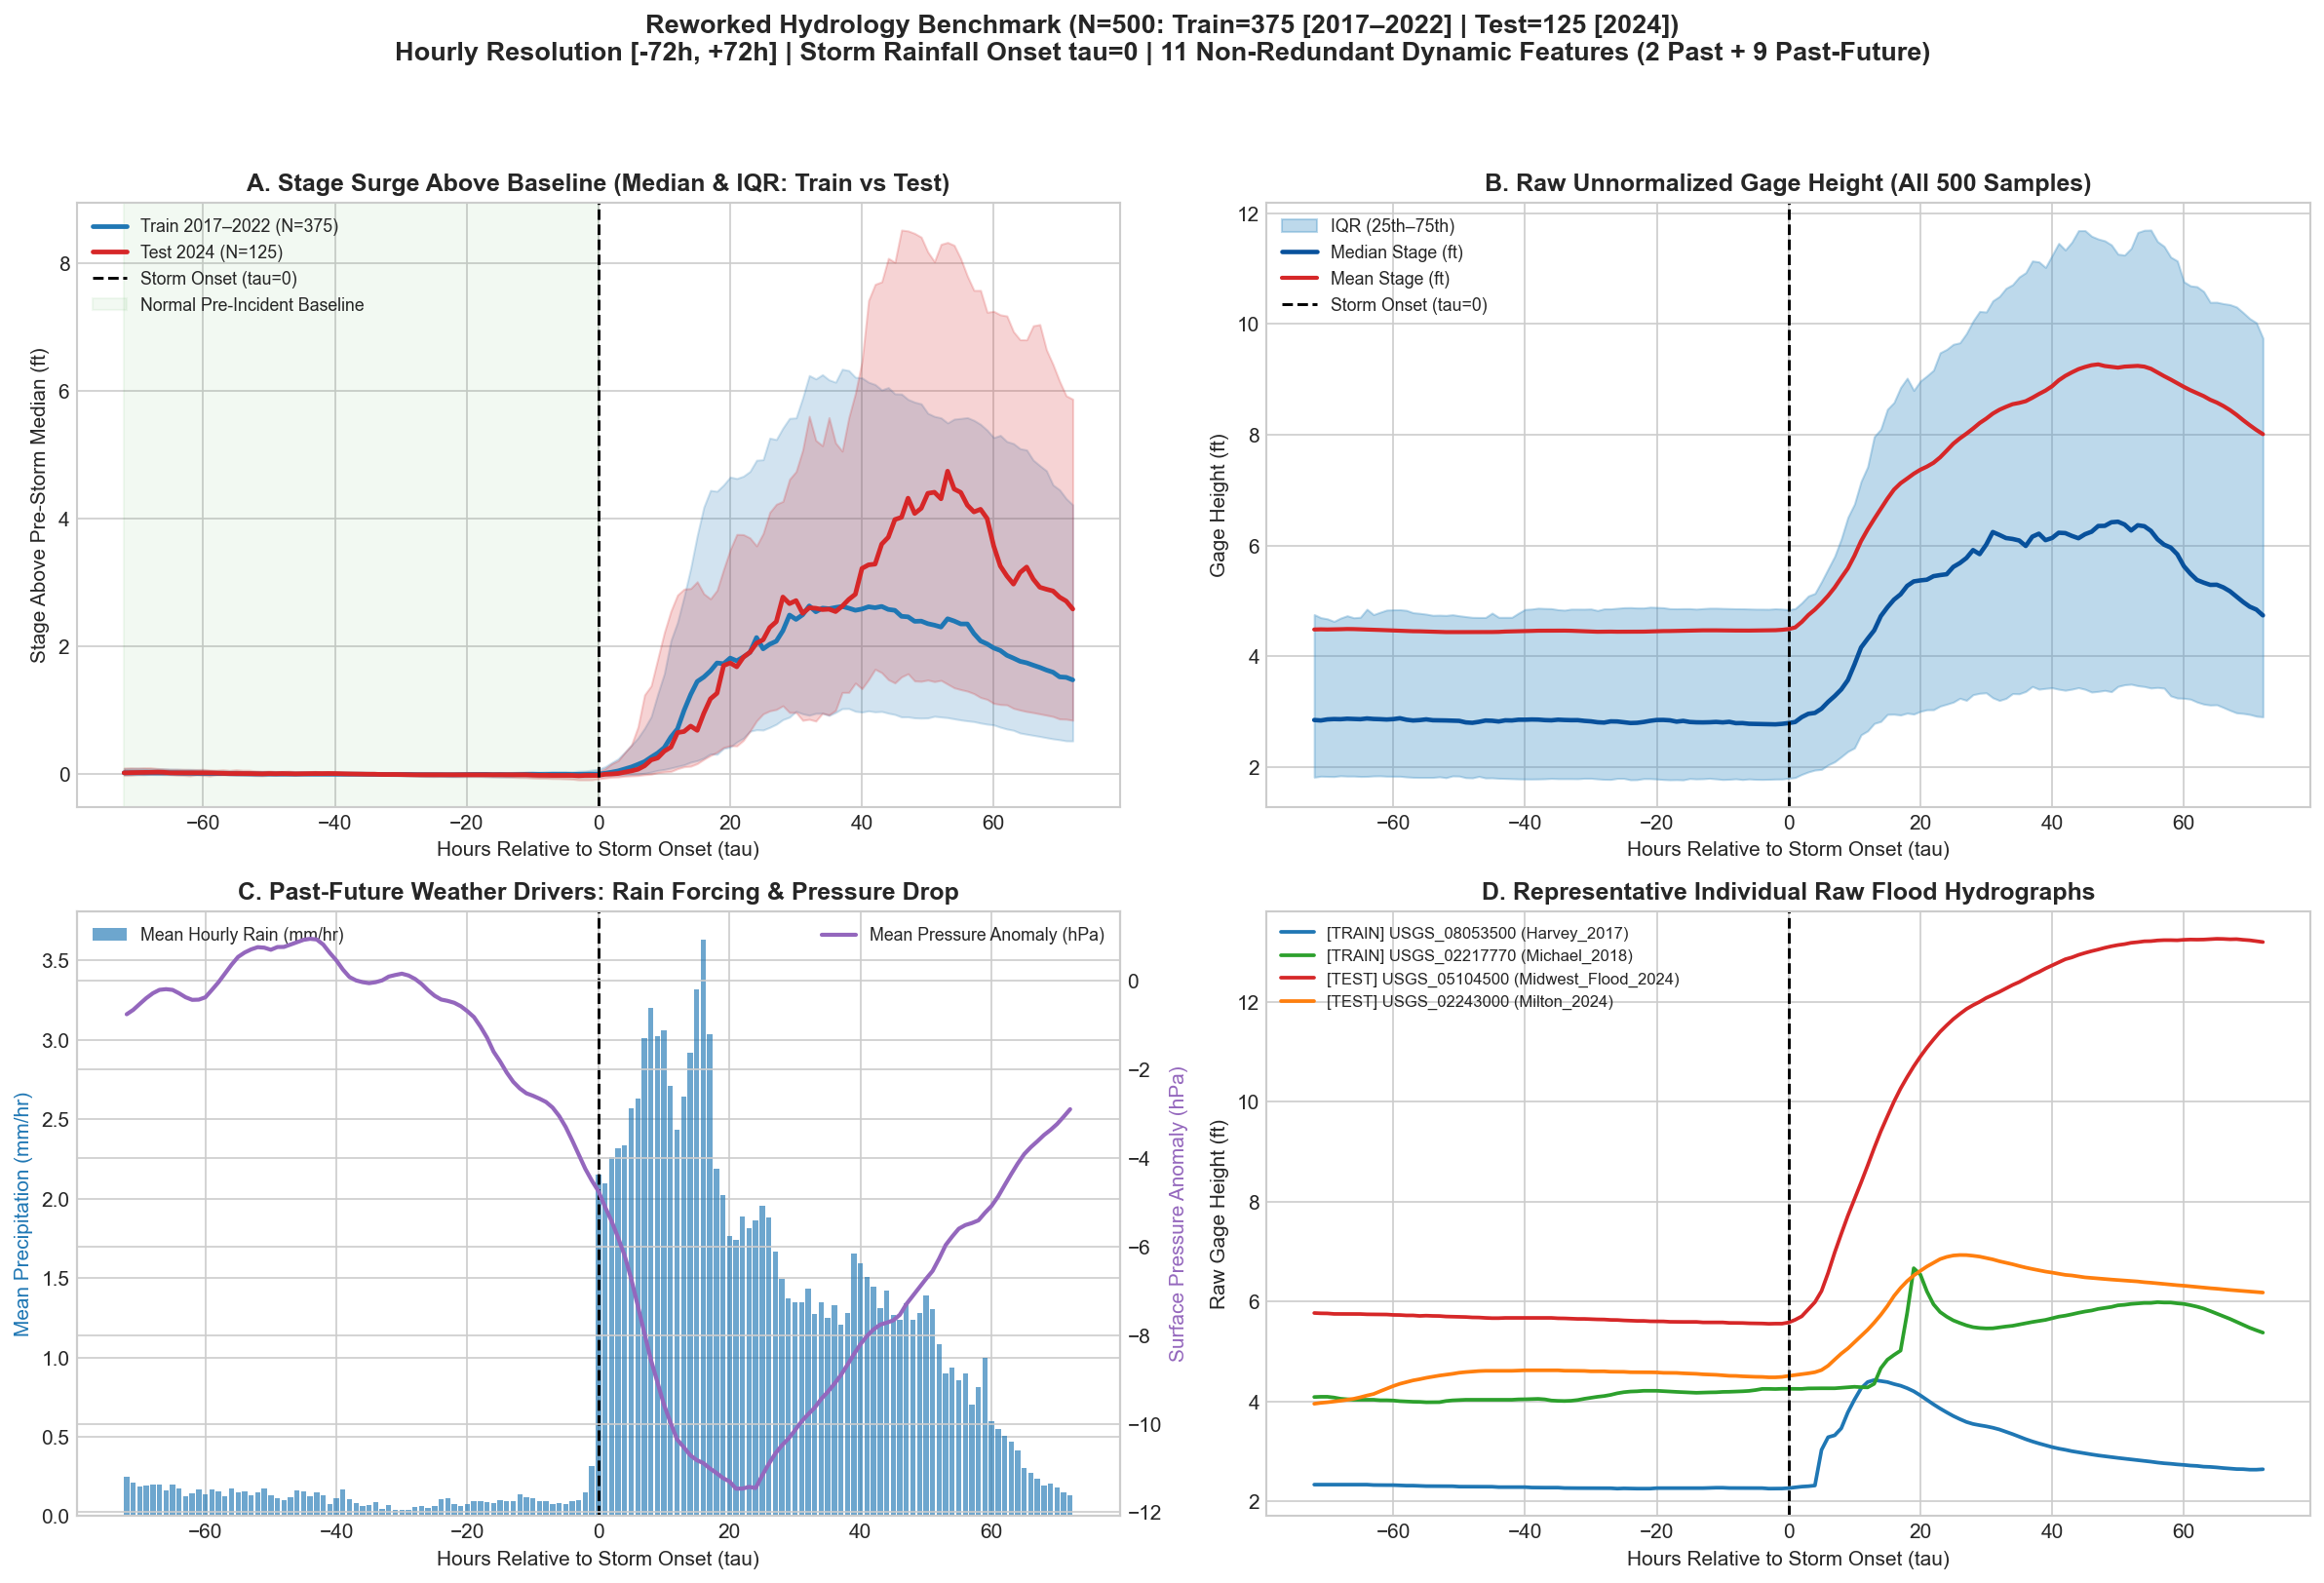

In [2]:
# Compute each river's normal pre-storm median stage (using hours tau < 0)
pre_storm_base = (
    df[df['tau_hour'] < 0]
    .groupby('sample_id')['stage_ft']
    .median()
    .rename('base_stage')
)
df = df.merge(pre_storm_base, on='sample_id')
df['stage_above_base'] = df['stage_ft'] - df['base_stage']

# Compute each river's pre-storm baseline pressure (first 24 hours) for pressure anomaly
base_press = (
    df[df['tau_hour'] <= -49]
    .groupby('sample_id')['pressure_hpa']
    .mean()
    .rename('base_press')
)
df = df.merge(base_press, on='sample_id')
df['pressure_anomaly_hpa'] = df['pressure_hpa'] - df['base_press']

fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=150)
fig.suptitle(
    "Reworked Hydrology Benchmark (N=500: Train=375 [2017–2022] | Test=125 [2024])\n"
    "Hourly Resolution [-72h, +72h] | Storm Rainfall Onset tau=0 | 11 Non-Redundant Dynamic Features (2 Past + 9 Past-Future)",
    fontsize=13, fontweight='bold', y=0.98
)

# --- Panel A: Stage Surge Above Pre-Storm Median (Train vs Test) ---
ax = axes[0, 0]
for split_name, label, col in [
    ('train', 'Train 2017–2022 (N=375)', '#1f77b4'),
    ('test',  'Test 2024 (N=125)',        '#d62728')
]:
    grp = df[df['split'] == split_name].groupby('tau_hour')['stage_above_base']
    med = grp.median()
    ax.plot(med.index, med.values, color=col, lw=2.3, label=label)
    ax.fill_between(med.index, grp.quantile(0.25), grp.quantile(0.75), color=col, alpha=0.2)

ax.axvline(0, color='black', ls='--', lw=1.4, label='Storm Onset (tau=0)')
ax.axvspan(-72, 0, color='#2ca02c', alpha=0.06, label='Normal Pre-Incident Baseline')
ax.set_title('A. Stage Surge Above Baseline (Median & IQR: Train vs Test)', fontweight='bold')
ax.set_xlabel('Hours Relative to Storm Onset (tau)')
ax.set_ylabel('Stage Above Pre-Storm Median (ft)')
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel B: Raw Unnormalized Stage Height (All 500 Rivers) ---
ax = axes[0, 1]
raw_grp = df.groupby('tau_hour')['stage_ft']
ax.fill_between(raw_grp.median().index, raw_grp.quantile(0.25), raw_grp.quantile(0.75),
                color='#4292c6', alpha=0.35, label='IQR (25th–75th)')
ax.plot(raw_grp.median().index, raw_grp.median().values, color='#08519c', lw=2.2, label='Median Stage (ft)')
ax.plot(raw_grp.mean().index, raw_grp.mean().values, color='#d62728', lw=2.0, label='Mean Stage (ft)')
ax.axvline(0, color='black', ls='--', lw=1.4, label='Storm Onset (tau=0)')
ax.set_title('B. Raw Unnormalized Gage Height (All 500 Samples)', fontweight='bold')
ax.set_xlabel('Hours Relative to Storm Onset (tau)')
ax.set_ylabel('Gage Height (ft)')
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel C: Mean Rainfall Forcing & Barometric Pressure Drop ---
ax = axes[1, 0]
rain_mean = df.groupby('tau_hour')['rain_mm_hr'].mean()
pres_mean = df.groupby('tau_hour')['pressure_anomaly_hpa'].mean()

ax.bar(rain_mean.index, rain_mean.values, color='#1f77b4', alpha=0.65, width=0.8, label='Mean Hourly Rain (mm/hr)')
ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('C. Past-Future Weather Drivers: Rain Forcing & Pressure Drop', fontweight='bold')
ax.set_xlabel('Hours Relative to Storm Onset (tau)')
ax.set_ylabel('Mean Precipitation (mm/hr)', color='#1f77b4')

ax_twin = ax.twinx()
ax_twin.plot(pres_mean.index, pres_mean.values, color='#9467bd', lw=2.0, label='Mean Pressure Anomaly (hPa)')
ax_twin.set_ylabel('Surface Pressure Anomaly (hPa)', color='#9467bd')
ax.legend(loc='upper left', fontsize=8.5)
ax_twin.legend(loc='upper right', fontsize=8.5)

# --- Panel D: 4 Representative Individual Flood Curves (2 Train + 2 Test) ---
ax = axes[1, 1]
sample_picks = [
    ('USGS_08053500__Harvey_2017',       '#1f77b4'),
    ('USGS_02217770__Michael_2018',      '#2ca02c'),
    ('USGS_05104500__Midwest_Flood_2024','#d62728'),
    ('USGS_02243000__Milton_2024',       '#ff7f0e'),
]
for sid, col in sample_picks:
    sub = df[df['sample_id'] == sid]
    split_tag = sub['split'].iloc[0].upper()
    storm_tag = sub['storm'].iloc[0]
    ax.plot(sub['tau_hour'], sub['stage_ft'], color=col, lw=1.8, label=f"[{split_tag}] {sid.split('__')[0]} ({storm_tag})")

ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('D. Representative Individual Raw Flood Hydrographs', fontweight='bold')
ax.set_xlabel('Hours Relative to Storm Onset (tau)')
ax.set_ylabel('Raw Gage Height (ft)')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('data/reworked_domain2_hydrology_verification.png', dpi=150)
plt.show()


### 3. What Happens Around $\tau = 0$ for Every Single Feature

Here we plot all **11 dynamic features** individually across `[-72h, +72h]` (median & IQR for `train` vs. `test`), plus the **2 static station features** in the final panel.
* **Blue / Red curves:** Median value at each hour relative to storm rain onset (`tau = 0`).
* **Shaded bands:** 25th–75th percentile (IQR) across all rivers.
* **Green shaded region (`tau < 0`):** Calm pre-storm baseline period.


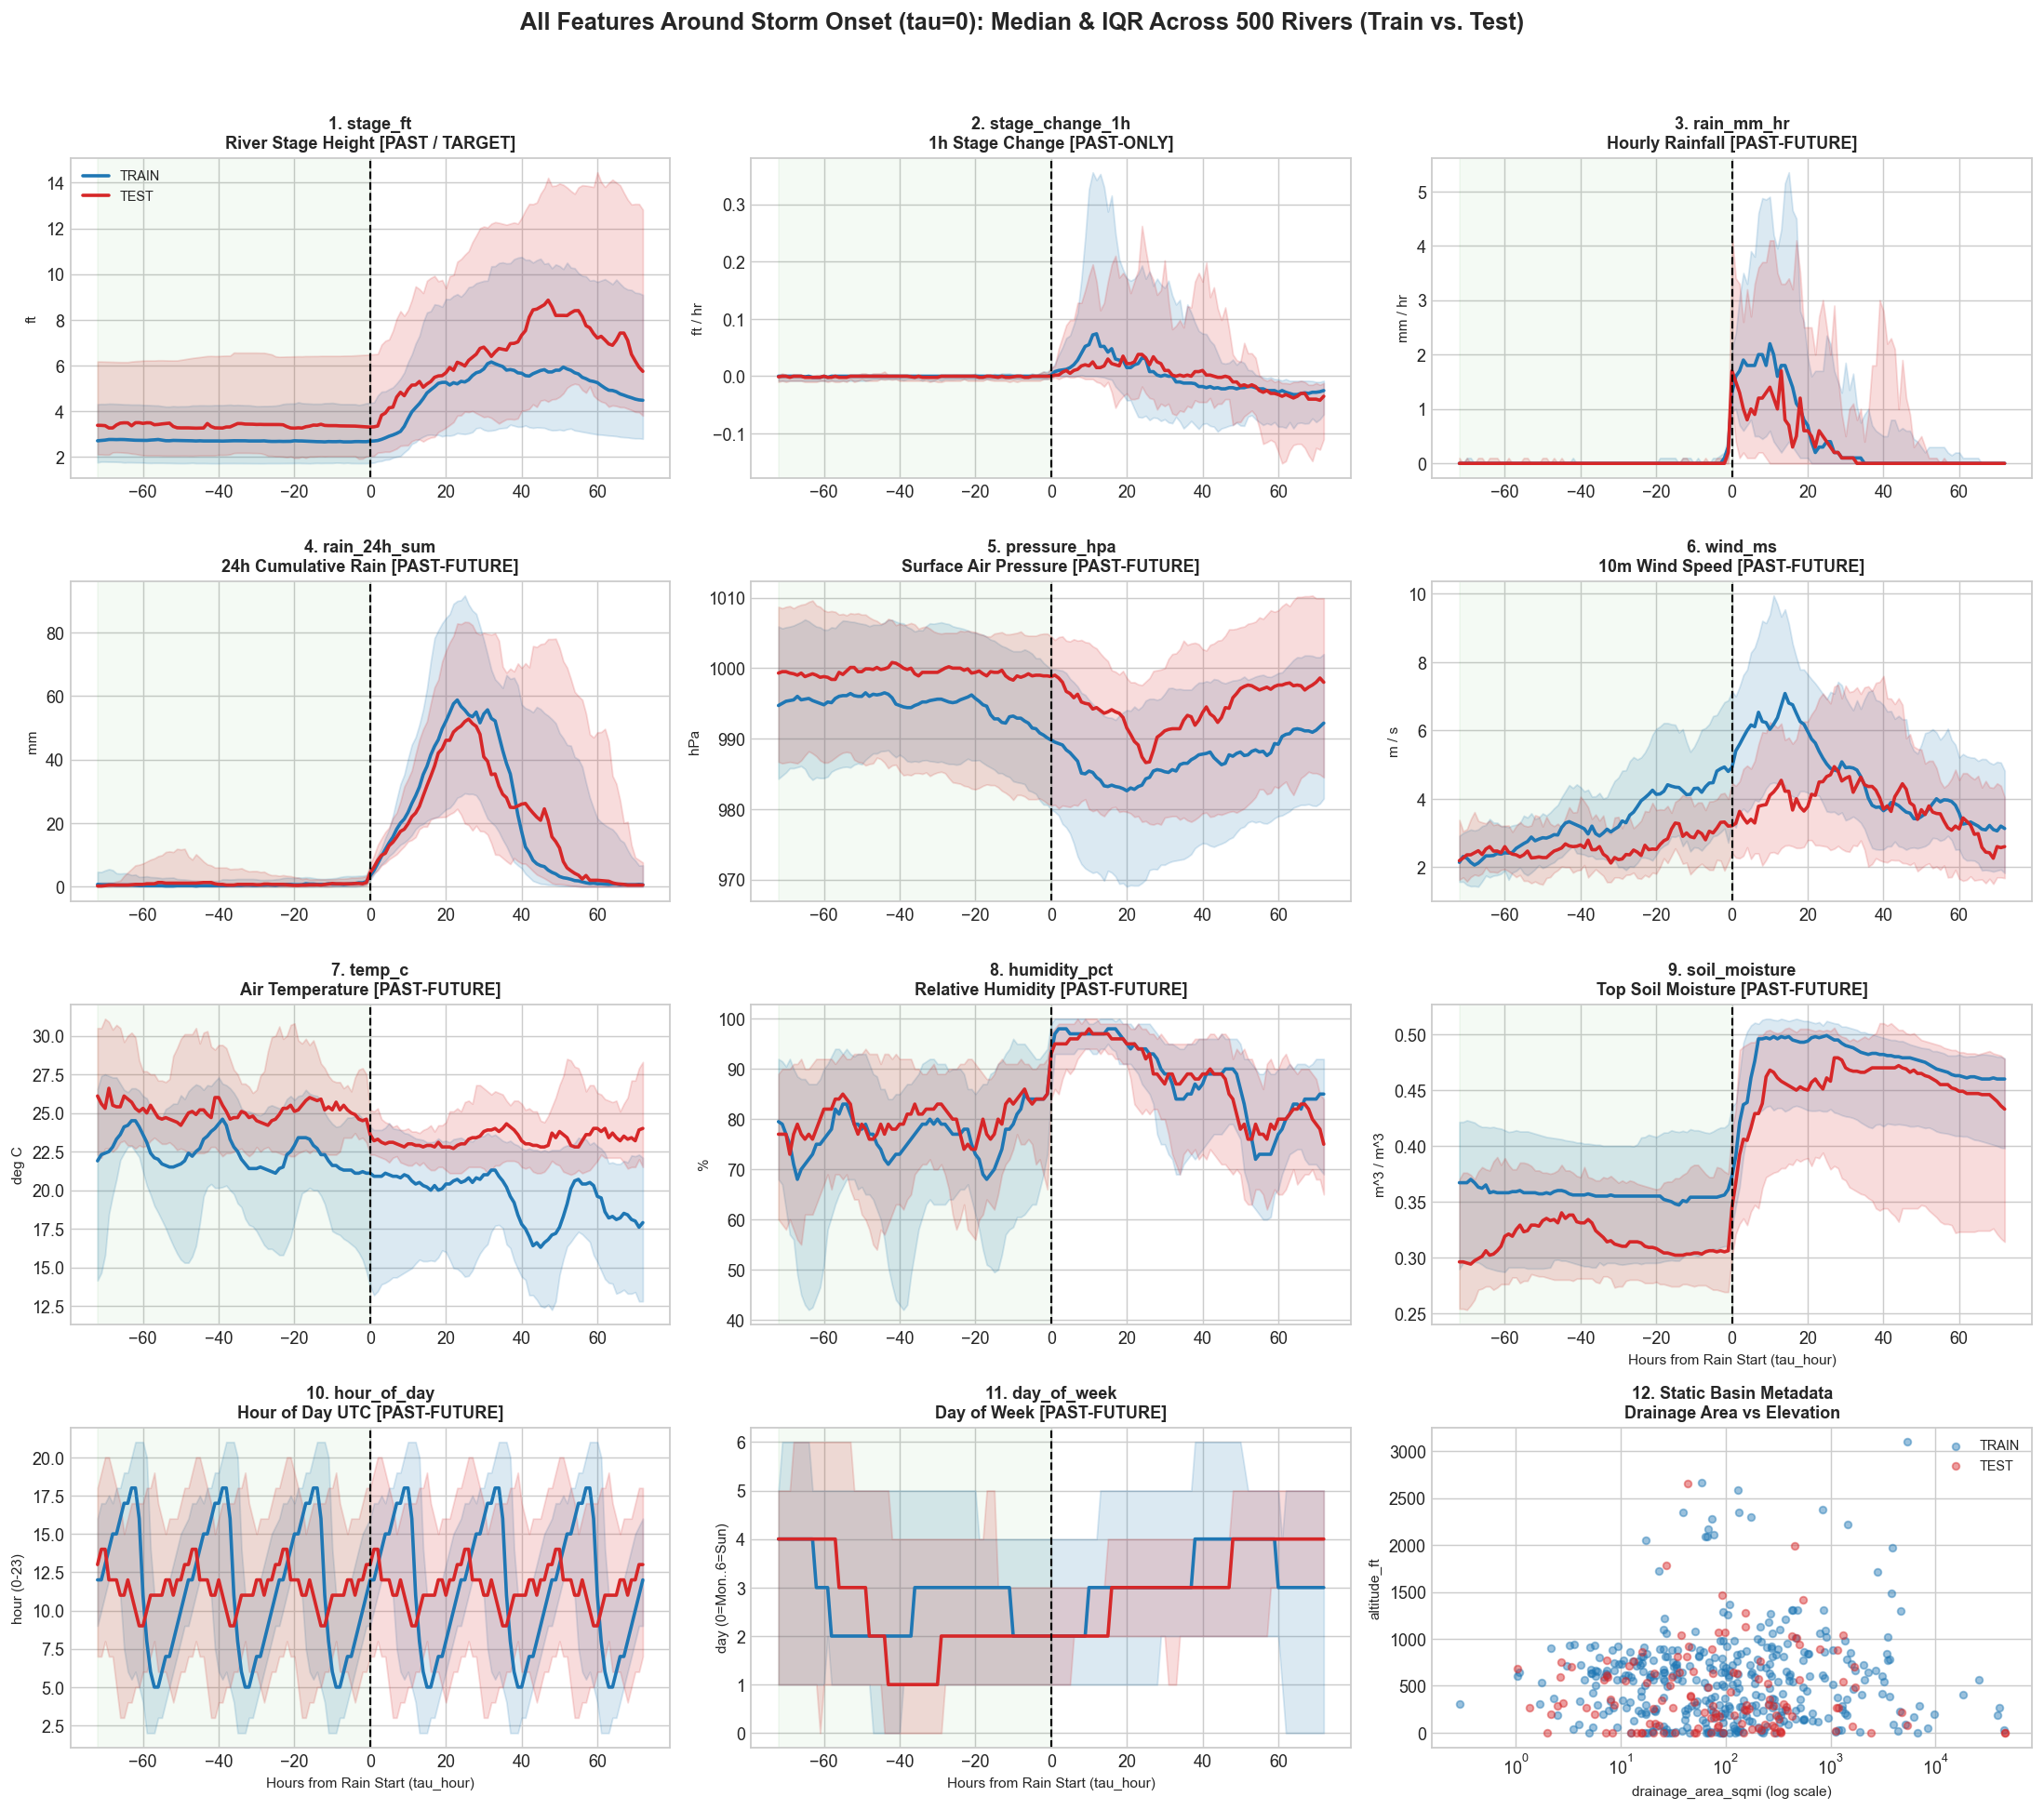

In [3]:
# Human-readable labels & units for each dynamic feature
feature_labels = {
    'stage_ft':        ('River Stage Height [PAST / TARGET]', 'ft'),
    'stage_change_1h': ('1h Stage Change [PAST-ONLY]', 'ft / hr'),
    'rain_mm_hr':      ('Hourly Rainfall [PAST-FUTURE]', 'mm / hr'),
    'rain_24h_sum':    ('24h Cumulative Rain [PAST-FUTURE]', 'mm'),
    'pressure_hpa':    ('Surface Air Pressure [PAST-FUTURE]', 'hPa'),
    'wind_ms':         ('10m Wind Speed [PAST-FUTURE]', 'm / s'),
    'temp_c':          ('Air Temperature [PAST-FUTURE]', 'deg C'),
    'humidity_pct':    ('Relative Humidity [PAST-FUTURE]', '%'),
    'soil_moisture':   ('Top Soil Moisture [PAST-FUTURE]', 'm^3 / m^3'),
    'hour_of_day':     ('Hour of Day UTC [PAST-FUTURE]', 'hour (0-23)'),
    'day_of_week':     ('Day of Week [PAST-FUTURE]', 'day (0=Mon..6=Sun)'),
}

all_dyn = PAST_FEATURES + PAST_FUTURE_FEATURES
fig, axes = plt.subplots(4, 3, figsize=(17, 15), dpi=130)
axes = axes.ravel()

# Plot each of the 11 dynamic features across tau = -72h .. +72h
for i, col in enumerate(all_dyn):
    ax = axes[i]
    title, unit = feature_labels[col]

    for split_name, line_col in [('train', '#1f77b4'), ('test', '#d62728')]:
        grp = df[df['split'] == split_name].groupby('tau_hour')[col]
        med = grp.median()
        ax.plot(med.index, med.values, color=line_col, lw=2.0, label=split_name.upper())
        ax.fill_between(med.index, grp.quantile(0.25), grp.quantile(0.75), color=line_col, alpha=0.16)

    # Mark storm rain onset tau = 0 and pre-storm baseline region
    ax.axvline(0, color='black', ls='--', lw=1.2)
    ax.axvspan(-72, 0, color='#2ca02c', alpha=0.05)
    ax.set_title(f"{i+1}. {col}\n{title}", fontsize=10, fontweight='bold')
    ax.set_ylabel(unit, fontsize=8.5)
    if i >= 8:
        ax.set_xlabel('Hours from Rain Start (tau_hour)', fontsize=8.5)
    if i == 0:
        ax.legend(loc='upper left', fontsize=8)

# Use the 12th panel to show the 2 static basin features (log-scale drainage area vs altitude)
ax_st = axes[11]
static_df = df.drop_duplicates('sample_id')
for split_name, col in [('train', '#1f77b4'), ('test', '#d62728')]:
    sub = static_df[static_df['split'] == split_name]
    ax_st.scatter(sub['drainage_area_sqmi'], sub['altitude_ft'], color=col, alpha=0.45, s=18, label=split_name.upper())
ax_st.set_xscale('log')
ax_st.set_title("12. Static Basin Metadata\nDrainage Area vs Elevation", fontsize=10, fontweight='bold')
ax_st.set_xlabel("drainage_area_sqmi (log scale)", fontsize=8.5)
ax_st.set_ylabel("altitude_ft", fontsize=8.5)
ax_st.legend(loc='upper right', fontsize=8)

fig.suptitle(
    "All Features Around Storm Onset (tau=0): Median & IQR Across 500 Rivers (Train vs. Test)",
    fontsize=14, fontweight='bold', y=0.995
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/reworked_hydrology_all_features_around_surge.png', dpi=150)
plt.show()


### 4. Detailed Single-River Walkthrough Across Key Features

Looking at **one individual test river** (`USGS_02112000__Helene_2024` in North Carolina) makes the cause-and-effect chain easy to see:
1. Before $\tau = 0$: calm river, dry air, high pressure.
2. At $\tau = 0$: rain begins, barometric pressure drops sharply, wind rises, soil saturates.
3. After $\tau = 0$: `stage_change_1h` spikes positive and `stage_ft` surges from `~2.3 ft` up to `>17 ft`.


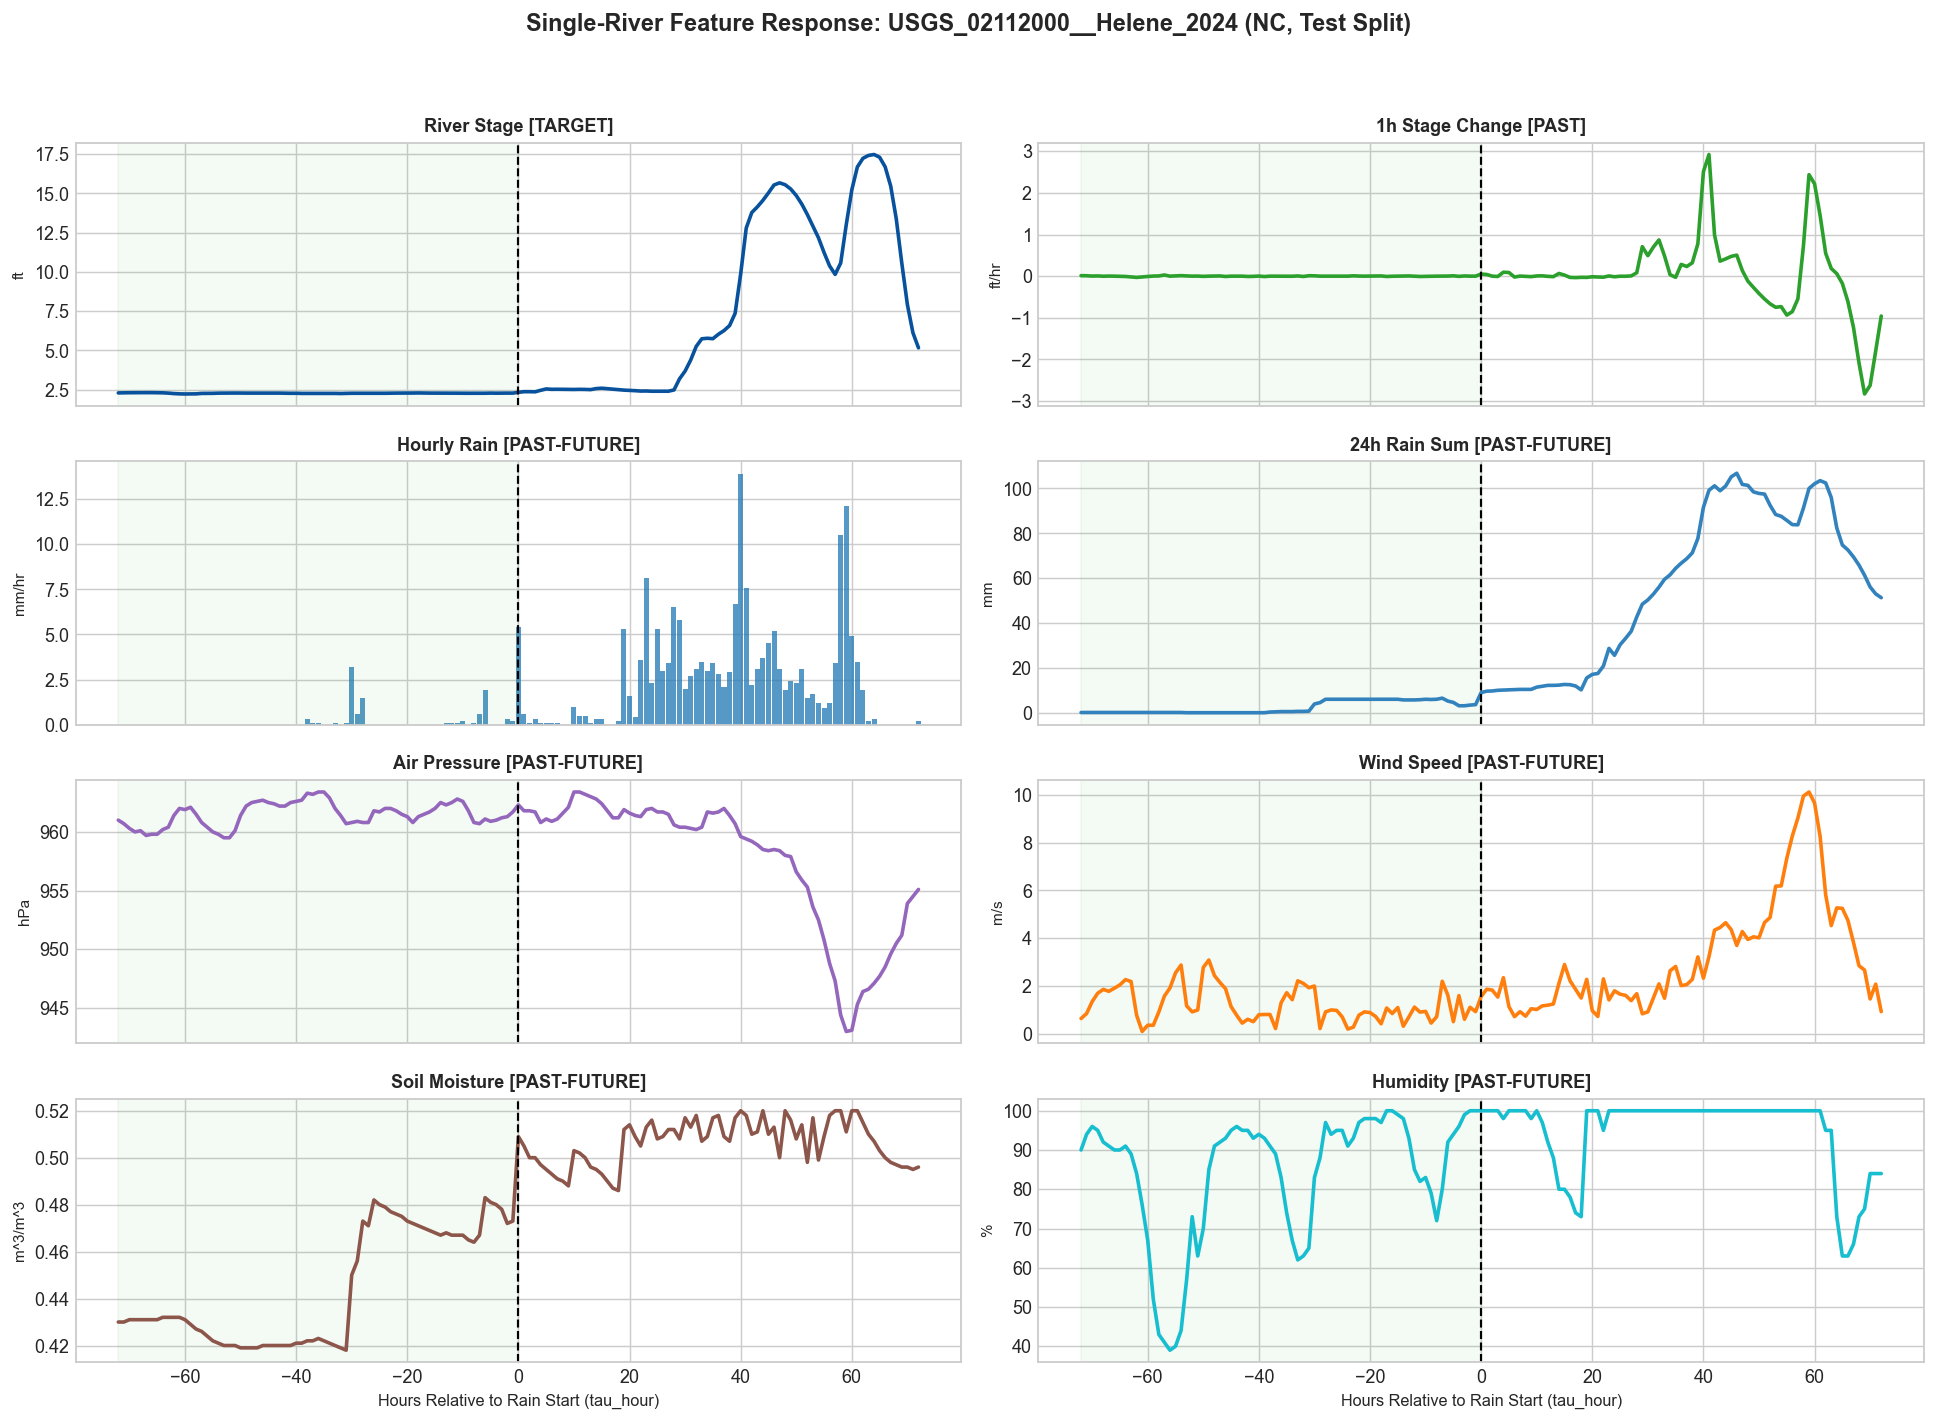

In [4]:
# Pick one clear Test-split flood curve from Hurricane Helene (2024)
one_sid = 'USGS_02112000__Helene_2024'
s = df[df['sample_id'] == one_sid].sort_values('tau_hour')

plot_specs = [
    ('stage_ft',      'River Stage [TARGET]',       '#08519c', 'ft'),
    ('stage_change_1h','1h Stage Change [PAST]',    '#2ca02c', 'ft/hr'),
    ('rain_mm_hr',    'Hourly Rain [PAST-FUTURE]',  '#1f77b4', 'mm/hr'),
    ('rain_24h_sum',  '24h Rain Sum [PAST-FUTURE]', '#3182bd', 'mm'),
    ('pressure_hpa',  'Air Pressure [PAST-FUTURE]', '#9467bd', 'hPa'),
    ('wind_ms',       'Wind Speed [PAST-FUTURE]',   '#ff7f0e', 'm/s'),
    ('soil_moisture', 'Soil Moisture [PAST-FUTURE]','#8c564b', 'm^3/m^3'),
    ('humidity_pct',  'Humidity [PAST-FUTURE]',     '#17becf', '%'),
]

fig, axes = plt.subplots(4, 2, figsize=(15, 11), dpi=130, sharex=True)
axes = axes.ravel()

for i, (col, label, color, unit) in enumerate(plot_specs):
    ax = axes[i]
    if col == 'rain_mm_hr':
        ax.bar(s['tau_hour'], s[col], color=color, alpha=0.75, width=0.9)
    else:
        ax.plot(s['tau_hour'], s[col], color=color, lw=2.0)

    ax.axvline(0, color='black', ls='--', lw=1.2)
    ax.axvspan(-72, 0, color='#2ca02c', alpha=0.05)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.set_ylabel(unit, fontsize=8.5)
    if i >= 6:
        ax.set_xlabel('Hours Relative to Rain Start (tau_hour)', fontsize=9)

fig.suptitle(f"Single-River Feature Response: {one_sid} (NC, Test Split)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('data/reworked_hydrology_single_river_features.png', dpi=150)
plt.show()


### 5. Before vs. After $\tau = 0$: Numerical Comparison Across All 500 Rivers

In [5]:
# Compare pre-storm (-72h to -1h) vs post-onset (+1h to +72h) distributions per feature
pre_df = df[df['tau_hour'] < 0]
post_df = df[df['tau_hour'] > 0]

summary_rows = []
for col in PAST_FEATURES + PAST_FUTURE_FEATURES:
    role = 'PAST-ONLY' if col in PAST_FEATURES else 'PAST-FUTURE'
    pre_med  = pre_df[col].median()
    post_med = post_df[col].median()
    pre_p90  = pre_df[col].quantile(0.90)
    post_p90 = post_df[col].quantile(0.90)
    summary_rows.append({
        'Feature': col,
        'Role': role,
        'Before_tau0_Median': round(float(pre_med), 3),
        'After_tau0_Median': round(float(post_med), 3),
        'Median_Shift': round(float(post_med - pre_med), 3),
        'Before_tau0_90th': round(float(pre_p90), 3),
        'After_tau0_90th': round(float(post_p90), 3),
    })

pd.DataFrame(summary_rows)


,Feature,Role,Before_tau0_Median,After_tau0_Median,Median_Shift,Before_tau0_90th,After_tau0_90th
0,stage_ft,PAST-ONLY,2.840,5.212,2.372,8.610,16.538
1,stage_change_1h,PAST-ONLY,0.000,-0.005,-0.005,0.012,0.338
2,rain_mm_hr,PAST-FUTURE,0.000,0.100,0.100,0.300,4.800
3,rain_24h_sum,PAST-FUTURE,0.600,18.400,17.800,8.900,96.100
4,pressure_hpa,PAST-FUTURE,995.700,988.600,-7.100,1011.200,1007.000
5,wind_ms,PAST-FUTURE,2.920,4.330,1.410,5.951,9.420
6,temp_c,PAST-FUTURE,23.300,21.300,-2.000,29.800,25.900
7,humidity_pct,PAST-FUTURE,78.000,91.000,13.000,97.000,100.000
8,soil_moisture,PAST-FUTURE,0.346,0.471,0.125,0.444,0.514
9,hour_of_day,PAST-FUTURE,11.500,11.500,0.000,21.000,21.000
